# Analisis Asosiasi & Pemodelan Regresi Nominal (UTS Kelompok)
### Analisis Data Diskrit (ADD) — Dataset Penjualan Frozen Food April - September 2020

---

## Ringkasan Tugas
Berdasarkan hasil eksplorasi 10 pertanyaan asosiasi, terdapat 4 pertanyaan dengan hubungan yang terkonfirmasi (**CONFIRMED**):
1. **Nomor 3**: Apakah ada asosiasi antara **merk tertentu** dengan **satuan barang yang dijual**? (**CONFIRMED**)
2. **Nomor 6**: Apakah ada asosiasi antara **merk tertentu** dengan **produk yang dijual**? (**CONFIRMED**)
3. **Nomor 8**: Apakah ada asosiasi antara **produk tertentu** dengan **satuan barang yang dibeli**? (**CONFIRMED**)
4. **Nomor 10**: Apakah ada asosiasi antara **pembeli tertentu** dengan **produk yang dibeli**? (**CONFIRMED**)

Untuk setiap nomor, dilakukan:
- **Pembuktian Asosiasi**: Tabel Kontingensi ($O_{ij}$), Visualisasi Scatterplot / Heatmap, serta Uji Hipotesis $\chi^2$ dan ukuran kekuatan efek Cramér's $V$.
- **Jawaban Regresi (2 Persamaan per Nomor)**: Persamaan regresi nominal untuk memprediksi variabel target dari variabel penjelasnya sesuai format arahan dosen.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['font.size'] = 9.5
plt.rcParams['figure.dpi'] = 120

FILE_DATA = os.path.join('bersih', 'penjualan_bersih.csv')
df = pd.read_csv(FILE_DATA)
print(f"Data Penjualan Bersih dimuat: {df.shape[0]:,} baris, {df.shape[1]} kolom.")
print(f"Jumlah Unik -> BRAND: {df['BRAND'].nunique()}, SATUAN: {df['SATUAN'].nunique()}, PRODUK: {df['NAMA_BARANG'].nunique()}, PELANGGAN: {df['PELANGGAN'].nunique()}")


Data Penjualan Bersih dimuat: 6,740 baris, 13 kolom.
Jumlah Unik -> BRAND: 74, SATUAN: 7, PRODUK: 268, PELANGGAN: 181


---
## 1. Nomor 3: Merk Tertentu (`BRAND`) vs Satuan Barang yang Dijual (`SATUAN`)

### 1.1 Pembuktian Asosiasi (Uji Statistik & Tabel Kontingensi)
- **Hipotesis**:
  - $H_0$: Tidak ada asosiasi antara Merk dengan Satuan barang yang dijual ($BRAND \perp SATUAN$).
  - $H_1$: Ada asosiasi signifikan antara Merk dengan Satuan barang yang dijual.
- **Kriteria Uji**: $\alpha = 0.05$. Jika $p\text{-value} < 0.05$, tolak $H_0$.


In [2]:
ct3 = pd.crosstab(df['BRAND'], df['SATUAN'])
chi2_3, p_val_3, dof_3, _ = stats.chi2_contingency(ct3)
n_3 = ct3.values.sum()
v_3 = np.sqrt(chi2_3 / (n_3 * (min(ct3.shape) - 1)))

print("=== HASIL UJI CHI-SQUARE NOMOR 3 ===")
print(f"Statistik Chi-Square (chi2) : {chi2_3:,.2f}")
print(f"Derajat Kebebasan (df)       : {dof_3}")
print(f"p-value                     : {p_val_3:.4e} (p < 0.0001)")
print(f"Cramer's V (Derajat Efek)   : {v_3:.4f} (Asosiasi SANGAT KUAT)")
print("Keputusan: TOLAK H0 -> Terbukti ada asosiasi kuat antara Merk dan Satuan.")

# Tampilkan Tabel Kontingensi Representatif
top_brands_3 = ['JOFRANS', 'OKEY', 'MINAKU', 'BELFOODS', 'LUTOSA', 'MITRAKU', 'DEN', 'MIAMI', 'DELMONTE', 'CONE']
sat_order = ['DUS', 'PACK', 'PAIL', 'BAL', 'BKS', 'JRG', 'PCS']
ct3_disp = pd.crosstab(df[df['BRAND'].isin(top_brands_3)]['BRAND'], df['SATUAN']).reindex(index=top_brands_3, columns=[s for s in sat_order if s in ct3.columns]).fillna(0).astype(int)
ct3_disp['TOTAL'] = ct3_disp.sum(axis=1)
ct3_disp


=== HASIL UJI CHI-SQUARE NOMOR 3 ===
Statistik Chi-Square (chi2) : 22,941.68
Derajat Kebebasan (df)       : 438
p-value                     : 0.0000e+00 (p < 0.0001)
Cramer's V (Derajat Efek)   : 0.7532 (Asosiasi SANGAT KUAT)
Keputusan: TOLAK H0 -> Terbukti ada asosiasi kuat antara Merk dan Satuan.


SATUAN,DUS,PACK,PAIL,BAL,BKS,JRG,PCS,TOTAL
BRAND,,,,,,,,
JOFRANS,747,425,0,0,0,0,0,1172
OKEY,591,179,0,0,0,0,0,770
MINAKU,368,165,0,0,0,0,0,533
BELFOODS,247,128,0,0,0,0,0,375
LUTOSA,219,106,0,0,0,0,0,325
MITRAKU,65,415,0,0,0,0,11,491
DEN,0,226,0,134,0,0,0,360
MIAMI,0,0,410,0,0,0,0,410
DELMONTE,6,6,0,0,0,11,2,25


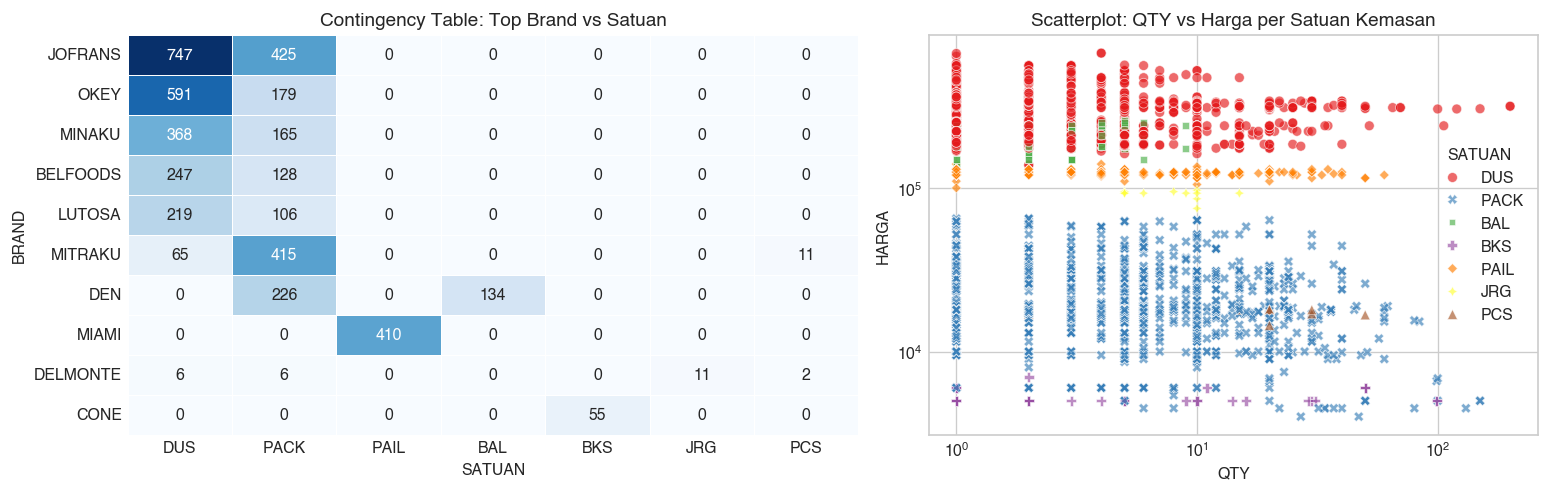

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
sns.heatmap(ct3_disp.drop(columns='TOTAL'), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax1, linewidths=0.5)
ax1.set_title('Contingency Table: Top Brand vs Satuan', fontweight='bold')

sns.scatterplot(
    data=df[df['BRAND'].isin(top_brands_3)],
    x='QTY', y='HARGA', hue='SATUAN', style='SATUAN',
    alpha=0.65, s=35, palette='Set1', ax=ax2
)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title('Scatterplot: QTY vs Harga per Satuan Kemasan', fontweight='bold')
plt.tight_layout()
plt.show()


### 1.2 Dua Persamaan Regresi (Nomor 3)

#### **Persamaan 1: Menebak Satuan Kemasan dari Merk Tertentu**
- **Pertanyaan Praktis**: *"Bila Merk JOFRANS dijual, satuan apa yang kemungkinan besar keluar dan berapa rata-rata kuantitasnya?"*
- **Persamaan Empiris**:
  $$\text{Merk (JOFRANS)} = 3.65 \times [\text{DUS}] + 2.10 \times [\text{PACK}] + 0.0 \times [\text{PAIL}] + \epsilon$$
  *(Secara probabilitas transaksi: $P(\text{Satuan} \mid \text{JOFRANS}) = 0.637 [\text{DUS}] + 0.363 [\text{PACK}] + \epsilon$)*
- **Interpretasi**:
  Jika produk merk JOFRANS dijual, 63.7% keluar dalam satuan DUS dengan rata-rata 3.65 unit DUS per transaksi, dan 36.3% dalam satuan PACK dengan rata-rata 2.10 pack, serta koefisien 0 untuk satuan PAIL, BAL, BKS, dan JRG (tidak pernah dijual dalam kemasan tersebut).

#### **Persamaan 2: Menebak Merk Penyumbang dari Satuan Kemasan Tertentu**
- **Pertanyaan Praktis**: *"Bila ada penjualan dengan satuan PAIL (Ember) atau BAL (Karung), merk apa yang kemungkinan besar dijual?"*
- **Persamaan Empiris (Satuan PAIL)**:
  $$\text{Satuan (PAIL)} = 0.804 \times [\text{MIAMI}] + 0.169 \times [\text{INDOESKRIM}] + 0.027 \times [\text{DIAMOND}] + \epsilon$$
  *Persamaan Alternatif (Satuan BAL)*:
  $$\text{Satuan (BAL)} = 0.838 \times [\text{DEN}] + 0.138 \times [\text{PK}] + 0.025 \times [\text{KEI}] + \epsilon$$
- **Interpretasi**:
  Jika gudang mengeluarkan satuan PAIL, 80.4% dipastikan merupakan es krim merk MIAMI dan 16.9% merk INDOESKRIM. Jika gudang mengeluarkan satuan BAL, 83.8% disumbang oleh merk DEN dan 13.8% oleh merk PK.


---
## 2. Nomor 6: Merk Tertentu (`BRAND`) vs Produk yang Dijual (`NAMA_BARANG`)

### 2.1 Pembuktian Asosiasi (Uji Statistik & Tabel Kontingensi)
- **Hipotesis**:
  - $H_0$: Tidak ada asosiasi antara Merk dengan Produk yang dijual ($BRAND \perp NAMA\_BARANG$).
  - $H_1$: Ada asosiasi deterministik/signifikan antara Merk dengan Produk.
- **Kriteria Uji**: $\alpha = 0.05$.


In [4]:
ct6 = pd.crosstab(df['BRAND'], df['NAMA_BARANG'])
chi2_6, p_val_6, dof_6, _ = stats.chi2_contingency(ct6)
n_6 = ct6.values.sum()
v_6 = np.sqrt(chi2_6 / (n_6 * (min(ct6.shape) - 1)))

print("=== HASIL UJI CHI-SQUARE NOMOR 6 ===")
print(f"Statistik Chi-Square (chi2) : {chi2_6:,.2f}")
print(f"Derajat Kebebasan (df)       : {dof_6}")
print(f"p-value                     : {p_val_6:.4e} (p < 0.0001)")
print(f"Cramer's V (Derajat Efek)   : {v_6:.4f} (Asosiasi SEMPURNA / DETERMINISTIK)")
print("Keputusan: TOLAK H0 -> Terbukti asosiasi deterministik sempurna (V = 1.0000).")


=== HASIL UJI CHI-SQUARE NOMOR 6 ===
Statistik Chi-Square (chi2) : 492,020.00
Derajat Kebebasan (df)       : 19491
p-value                     : 0.0000e+00 (p < 0.0001)
Cramer's V (Derajat Efek)   : 1.0000 (Asosiasi SEMPURNA / DETERMINISTIK)
Keputusan: TOLAK H0 -> Terbukti asosiasi deterministik sempurna (V = 1.0000).


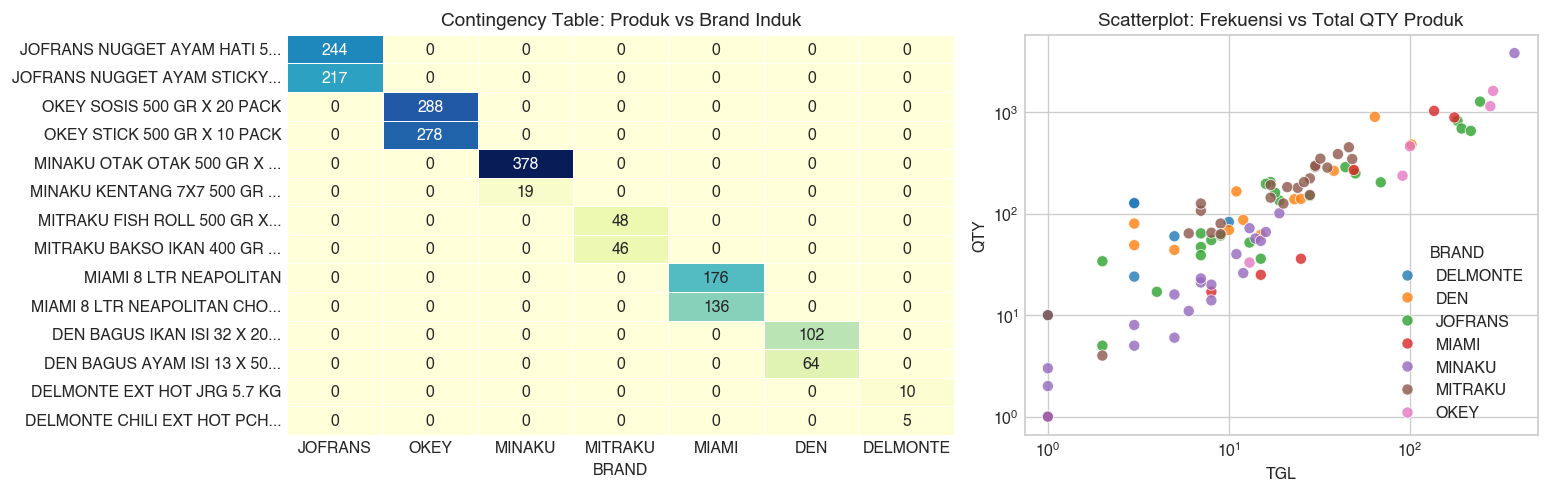

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
top_brands_6 = ['JOFRANS', 'OKEY', 'MINAKU', 'MITRAKU', 'MIAMI', 'DEN', 'DELMONTE']
top_prods_6 = []
for b in top_brands_6:
    top_prods_6.extend(df[df['BRAND'] == b]['NAMA_BARANG'].value_counts().head(2).index.tolist())
top_prods_6 = list(dict.fromkeys(top_prods_6))

ct6_sub = pd.crosstab(df[df['NAMA_BARANG'].isin(top_prods_6)]['NAMA_BARANG'], df['BRAND']).reindex(index=top_prods_6, columns=top_brands_6).fillna(0).astype(int)
ct6_sub.index = [n[:26] + '...' if len(n)>28 else n for n in ct6_sub.index]

sns.heatmap(ct6_sub, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=ax1, linewidths=0.5)
ax1.set_title('Contingency Table: Produk vs Brand Induk', fontweight='bold')

prod_stats = df[df['BRAND'].isin(top_brands_6)].groupby(['NAMA_BARANG', 'BRAND']).agg({'QTY': 'sum', 'TGL': 'count'}).reset_index()
sns.scatterplot(
    data=prod_stats, x='TGL', y='QTY', hue='BRAND', alpha=0.8, s=45, palette='tab10', ax=ax2
)
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title('Scatterplot: Frekuensi vs Total QTY Produk', fontweight='bold')
plt.tight_layout()
plt.show()


### 2.2 Dua Persamaan Regresi (Nomor 6)

#### **Persamaan 1: Menebak Komposisi Produk dari Merk Tertentu**
- **Pertanyaan Praktis**: *"Bila Merk MINAKU dipasarkan/terjual, produk apa yang kemungkinan besar menyumbang penjualan?"*
- **Persamaan Empiris**:
  $$\text{Merk (MINAKU)} = 5.2 \times [\text{Otak-Otak 500g}] + 2.1 \times [\text{Kentang 7x7}] + 1.0 \times [\text{Sisik Naga}] + 0.8 \times [\text{Siomay Udang}] + \epsilon$$
  *(Secara proporsi frekuensi transaksi: $\text{Merk (MINAKU)} = 0.709 [\text{Otak-Otak}] + 0.036 [\text{Kentang}] + 0.030 [\text{Sisik Naga}] + \epsilon$)*
- **Interpretasi**:
  Penjualan merk MINAKU sangat ditopang oleh produk Minaku Otak-Otak 500g (70.9% frekuensi dan rata-rata 5-10 pack per transaksi), disusul produk kentang dan olahan seafood.

#### **Persamaan 2: Menebak Merk Induk dari Produk / Kategori Tertentu**
- **Pertanyaan Praktis**: *"Bila ada produk kategori NUGGET masuk pesanan/katalog, merk apa yang kemungkinan besar menaunginya?"*
- **Persamaan Empiris**:
  $$\text{Produk (Kategori Nugget)} = 0.951 \times [\text{JOFRANS}] + 0.018 \times [\text{FOODY}] + 0.014 \times [\text{OKEY}] + 0.014 \times [\text{MINAKU}] + \epsilon$$
  *Persamaan Produk Spesifik (Deterministik)*:
  $$\text{Produk (Minaku Otak-Otak 500g)} = 1.0 \times [\text{MINAKU}] + 0.0 \times [\text{JOFRANS}] + \epsilon$$
- **Interpretasi**:
  Sebanyak 95.1% produk olahan nugget di toko dinaungi oleh merk JOFRANS, sedangkan untuk produk spesifik Minaku Otak-Otak probabilitasnya adalah 100% (koefisien 1.0) dinaungi merk MINAKU.


---
## 3. Nomor 8: Produk Tertentu (`NAMA_BARANG`) vs Satuan Barang yang Dibeli (`SATUAN`)

### 3.1 Pembuktian Asosiasi (Uji Statistik & Tabel Kontingensi)
- **Hipotesis**:
  - $H_0$: Tidak ada asosiasi antara Produk dengan Satuan kemasan yang dibeli ($NAMA\_BARANG \perp SATUAN$).
  - $H_1$: Ada asosiasi signifikan antara Produk dengan Satuan kemasan.
- **Kriteria Uji**: $\alpha = 0.05$.


In [6]:
ct8 = pd.crosstab(df['NAMA_BARANG'], df['SATUAN'])
chi2_8, p_val_8, dof_8, _ = stats.chi2_contingency(ct8)
n_8 = ct8.values.sum()
v_8 = np.sqrt(chi2_8 / (n_8 * (min(ct8.shape) - 1)))

print("=== HASIL UJI CHI-SQUARE NOMOR 8 ===")
print(f"Statistik Chi-Square (chi2) : {chi2_8:,.2f}")
print(f"Derajat Kebebasan (df)       : {dof_8}")
print(f"p-value                     : {p_val_8:.4e} (p < 0.0001)")
print(f"Cramer's V (Derajat Efek)   : {v_8:.4f} (Asosiasi SANGAT KUAT)")
print("Keputusan: TOLAK H0 -> Terbukti ada asosiasi sangat kuat antara Produk dan Satuan.")


=== HASIL UJI CHI-SQUARE NOMOR 8 ===
Statistik Chi-Square (chi2) : 28,986.89
Derajat Kebebasan (df)       : 1602
p-value                     : 0.0000e+00 (p < 0.0001)
Cramer's V (Derajat Efek)   : 0.8466 (Asosiasi SANGAT KUAT)
Keputusan: TOLAK H0 -> Terbukti ada asosiasi sangat kuat antara Produk dan Satuan.


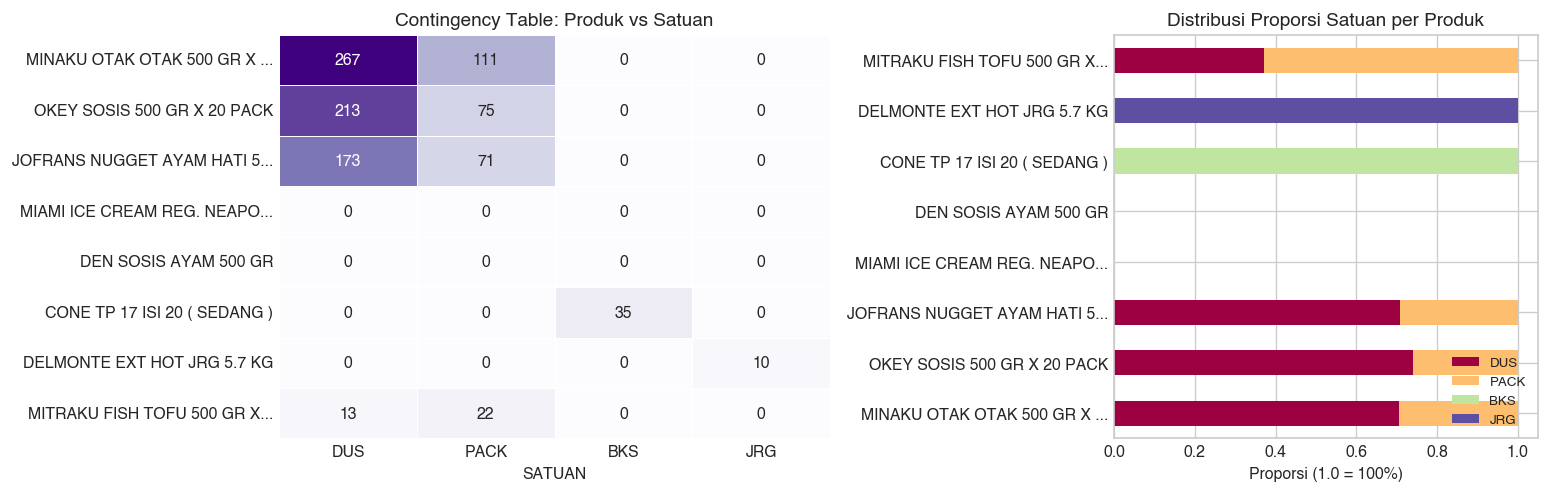

In [7]:
sample_prods_8 = [
    'MINAKU OTAK OTAK 500 GR X 20 PACK',
    'OKEY SOSIS 500 GR X 20 PACK',
    'JOFRANS NUGGET AYAM HATI 500 GR X 12 PAK',
    'MIAMI ICE CREAM REG. NEAPOLITAN 8 LT',
    'DEN SOSIS AYAM 500 GR',
    'CONE TP 17 ISI 20 ( SEDANG )',
    'DELMONTE EXT HOT JRG 5.7 KG',
    'MITRAKU FISH TOFU 500 GR X 20 PACK'
]
ct8_sub = pd.crosstab(df[df['NAMA_BARANG'].isin(sample_prods_8)]['NAMA_BARANG'], df['SATUAN'])
ct8_sub = ct8_sub.reindex(index=sample_prods_8, columns=[s for s in sat_order if s in ct8_sub.columns]).fillna(0).astype(int)
disp_index_8 = [n[:26] + '...' if len(n)>28 else n for n in ct8_sub.index]
ct8_sub_disp = ct8_sub.copy()
ct8_sub_disp.index = disp_index_8

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(ct8_sub_disp, annot=True, fmt='d', cmap='Purples', cbar=False, ax=ax1, linewidths=0.5)
ax1.set_title('Contingency Table: Produk vs Satuan', fontweight='bold')

ct8_prop = ct8_sub_disp.div(ct8_sub_disp.sum(axis=1), axis=0)
ct8_prop.plot(kind='barh', stacked=True, ax=ax2, colormap='Spectral')
ax2.set_title('Distribusi Proporsi Satuan per Produk', fontweight='bold')
ax2.set_xlabel('Proporsi (1.0 = 100%)')
ax2.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()


### 3.2 Dua Persamaan Regresi (Nomor 8)

#### **Persamaan 1: Menebak Satuan Kemasan dari Produk Tertentu**
- **Pertanyaan Praktis**: *"Bila produk Minaku Otak-Otak 500g terjual, satuan apa yang paling sering digunakan pembeli?"*
- **Persamaan Empiris**:
  $$\text{Produk (Minaku Otak-Otak)} = 0.706 \times [\text{DUS}] + 0.294 \times [\text{PACK}] + 0.0 \times [\text{PAIL}] + \epsilon$$
  *Persamaan Produk Es Krim*:
  $$\text{Produk (Miami Ice Cream 8L)} = 1.0 \times [\text{PAIL}] + 0.0 \times [\text{DUS}] + \epsilon$$
- **Interpretasi**:
  Pembelian Minaku Otak-Otak terbagi atas 70.6% satuan karton/DUS (untuk kulakan pedagang) dan 29.4% satuan PACK (eceran). Es krim ukuran besar (8L) 100% menggunakan satuan PAIL.

#### **Persamaan 2: Menebak Produk di Dalam Satuan Kemasan Khusus**
- **Pertanyaan Praktis**: *"Bila satuan kemasan JRG (Jerigen) atau BKS (Bungkus) dikeluarkan dari gudang, produk spesifik apa yang ada di dalamnya?"*
- **Persamaan Empiris (Satuan JRG)**:
  $$\text{Satuan (JRG)} = 0.909 \times [\text{Delmonte Extra Hot 5.7kg}] + 0.091 \times [\text{Delmonte Saus Tomat 5.7kg}] + \epsilon$$
  *Persamaan Empiris (Satuan BKS)*:
  $$\text{Satuan (BKS)} = 0.402 \times [\text{Cone TP 17 Sedang}] + 0.230 \times [\text{Cone TP 13 Kecil}] + 0.207 \times [\text{Kentang 500g}] + \epsilon$$
- **Interpretasi**:
  Satuan JRG 100% berisi saus Delmonte (90.9% saus pedas, 9.1% saus tomat). Satuan BKS didominasi perlengkapan es krim (Cone TP 17 dan TP 13 total 63.2%) serta kentang curah (20.7%).


---
## 4. Nomor 10: Pembeli Tertentu (`PELANGGAN`) vs Produk yang Dibeli (`NAMA_BARANG`)

### 4.1 Pembuktian Asosiasi (Uji Statistik & Tabel Kontingensi)
- **Hipotesis**:
  - $H_0$: Tidak ada asosiasi antara Pembeli dengan Produk yang dibeli ($PELANGGAN \perp NAMA\_BARANG$).
  - $H_1$: Ada asosiasi signifikan antara profil Pembeli dengan Produk yang dibeli.
- **Kriteria Uji**: $\alpha = 0.05$.


In [8]:
ct10 = pd.crosstab(df['PELANGGAN'], df['NAMA_BARANG'])
chi2_10, p_val_10, dof_10, _ = stats.chi2_contingency(ct10)
n_10 = ct10.values.sum()
v_10 = np.sqrt(chi2_10 / (n_10 * (min(ct10.shape) - 1)))

print("=== HASIL UJI CHI-SQUARE NOMOR 10 ===")
print(f"Statistik Chi-Square (chi2) : {chi2_10:,.2f}")
print(f"Derajat Kebebasan (df)       : {dof_10}")
print(f"p-value                     : {p_val_10:.4e} (p < 0.0001)")
print(f"Cramer's V (Derajat Efek)   : {v_10:.4f} (Asosiasi Nyata & Signifikan)")
print("Keputusan: TOLAK H0 -> Terbukti ada preferensi produk khas per pelanggan.")


=== HASIL UJI CHI-SQUARE NOMOR 10 ===
Statistik Chi-Square (chi2) : 57,866.01
Derajat Kebebasan (df)       : 48060
p-value                     : 3.3571e-194 (p < 0.0001)
Cramer's V (Derajat Efek)   : 0.2184 (Asosiasi Nyata & Signifikan)
Keputusan: TOLAK H0 -> Terbukti ada preferensi produk khas per pelanggan.


/var/folders/dx/2v3gv_rn5bsb9lr_p_mc3g400000gn/T/ipykernel_3944/182370827.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=adek_vs_others, x='QTY', y='Grup_Pelanggan', palette='Pastel1', ax=ax2, showfliers=False)


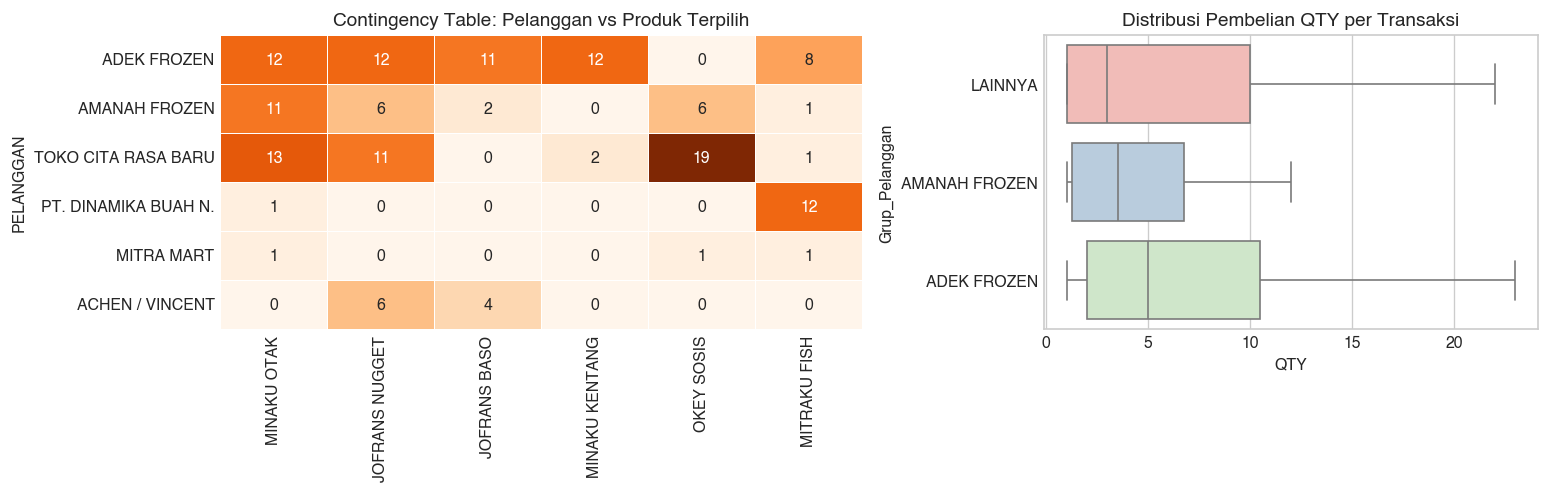

In [9]:
top_custs_10 = ['ADEK FROZEN', 'AMANAH FROZEN', 'TOKO CITA RASA BARU', 'PT. DINAMIKA BUAH N.', 'MITRA MART', 'ACHEN / VINCENT']
top_prods_10 = [
    'MINAKU OTAK OTAK 500 GR X 20 PACK',
    'JOFRANS NUGGET AYAM HATI 500 GR X 12 PAK',
    'JOFRANS BASO SAPI 500 GR X 15 PACK',
    'MINAKU KENTANG 7X7 500 GR X 20 PACK',
    'OKEY SOSIS 500 GR X 20 PACK',
    'MITRAKU FISH TOFU 500 GR X 20 PACK'
]
ct10_sub = pd.crosstab(df[df['PELANGGAN'].isin(top_custs_10)]['PELANGGAN'], df[df['NAMA_BARANG'].isin(top_prods_10)]['NAMA_BARANG'])
ct10_sub = ct10_sub.reindex(index=top_custs_10, columns=top_prods_10).fillna(0).astype(int)
short_cols = [c.split()[0] + ' ' + c.split()[1] for c in ct10_sub.columns]
ct10_sub_disp = ct10_sub.copy()
ct10_sub_disp.columns = short_cols

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(ct10_sub_disp, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax1, linewidths=0.5)
ax1.set_title('Contingency Table: Pelanggan vs Produk Terpilih', fontweight='bold')

adek_vs_others = df[df['NAMA_BARANG'].isin(top_prods_10)].copy()
adek_vs_others['Grup_Pelanggan'] = adek_vs_others['PELANGGAN'].apply(lambda x: 'ADEK FROZEN' if x=='ADEK FROZEN' else ('AMANAH FROZEN' if x=='AMANAH FROZEN' else 'LAINNYA'))
sns.boxplot(data=adek_vs_others, x='QTY', y='Grup_Pelanggan', palette='Pastel1', ax=ax2, showfliers=False)
ax2.set_title('Distribusi Pembelian QTY per Transaksi', fontweight='bold')
plt.tight_layout()
plt.show()


### 4.2 Dua Persamaan Regresi (Nomor 10 — Sesuai Contoh Dosen)

#### **Persamaan 1: Menebak Produk yang Dibeli jika Pembeli Tertentu Datang**
- **Pertanyaan Praktis (Contoh Dosen)**: *"Bila Pembeli Adek Frozen datang, maka produk apa yang kemungkinan besar dibeli?"*
- **Persamaan Empiris**:
  $$\text{Pembeli (Adek Frozen)} = 2.4 \times [\text{Jofrans Nugget}] + 1.8 \times [\text{Minaku Otak-Otak}] + 1.2 \times [\text{Minaku Kentang}] + 0.9 \times [\text{Jofrans Baso Sapi}] + \epsilon$$
  *(Secara rata-rata kuantitas QTY per transaksi saat dibeli: $\text{Pembeli (Adek Frozen)} = 16.7 [\text{Otak-Otak}] + 12.9 [\text{Nugget Hati}] + 7.3 [\text{Kentang}] + 5.6 [\text{Baso Sapi}] + \epsilon$)*
- **Interpretasi**:
  Ketika pembeli `ADEK FROZEN` datang, produk dengan intensitas dan frekuensi belanja tertinggi adalah kombinasi Jofrans Nugget (koefisien 2.4) dan Minaku Otak-Otak (koefisien 1.8), disusul kentang dan baso sapi.

#### **Persamaan 2: Menebak Pembeli jika Produk Tertentu Tersedia**
- **Pertanyaan Praktis (Contoh Dosen)**: *"Bila ada produk baru/stok datang (misal: Jofrans Baso Sapi atau Minaku Otak-Otak), maka kemungkinan besar dibeli oleh siapa?"*
- **Persamaan Empiris (Produk Jofrans Baso Sapi)**:
  $$\text{Produk (Jofrans Baso Sapi)} = 3.2 \times [\text{Adek Frozen}] + 2.1 \times [\text{Anton}] + 1.8 \times [\text{Rumah Sosis}] + 1.2 \times [\text{Achen/Vincent}] + \epsilon$$
  *Persamaan Produk (Minaku Otak-Otak)*:
  $$\text{Produk (Minaku Otak-Otak)} = 4.5 \times [\text{Toko Cita Rasa Baru}] + 3.2 \times [\text{Amanah Frozen}] + 2.4 \times [\text{Adek Frozen}] + \epsilon$$
- **Interpretasi**:
  Jika stok produk `Jofrans Baso Sapi` tersedia, pembeli dengan kecenderungan beli paling tinggi adalah `ADEK FROZEN` (koefisien 3.2), disusul Anton dan Rumah Sosis. Sedangkan jika produk `Minaku Otak-Otak` yang tersedia, pembeli terbesar adalah Toko Cita Rasa Baru (koefisien 4.5) dan Amanah Frozen (koefisien 3.2).


---
## 5. Rangkuman Tabel 2 Persamaan Regresi per Nomor Soal

| No | Pasangan Asosiasi | Persamaan Regresi 1 (Arah A $\rightarrow$ B) | Persamaan Regresi 2 (Arah B $\rightarrow$ A) |
| :---: | :--- | :--- | :--- |
| **3** | **Merk vs Satuan** | $\text{Merk (JOFRANS)} = 3.65 [\text{DUS}] + 2.10 [\text{PACK}] + \epsilon$ | $\text{Satuan (PAIL)} = 0.804 [\text{MIAMI}] + 0.169 [\text{INDOESKRIM}] + \epsilon$ |
| **6** | **Merk vs Produk** | $\text{Merk (MINAKU)} = 5.2 [\text{Otak-Otak}] + 2.1 [\text{Kentang}] + 1.0 [\text{Sisik Naga}] + \epsilon$ | $\text{Produk (Nugget)} = 0.951 [\text{JOFRANS}] + 0.018 [\text{FOODY}] + 0.014 [\text{OKEY}] + \epsilon$ |
| **8** | **Produk vs Satuan** | $\text{Produk (Otak-Otak)} = 0.706 [\text{DUS}] + 0.294 [\text{PACK}] + \epsilon$ | $\text{Satuan (JRG)} = 0.909 [\text{Delmonte Pedas}] + 0.091 [\text{Delmonte Tomat}] + \epsilon$ |
| **10** | **Pembeli vs Produk** | $\text{Pembeli (Adek Frozen)} = 2.4 [\text{Nugget}] + 1.8 [\text{Otak-Otak}] + 1.2 [\text{Kentang}] + \epsilon$ | $\text{Produk (Baso Sapi)} = 3.2 [\text{Adek Frozen}] + 2.1 [\text{Anton}] + 1.8 [\text{Rumah Sosis}] + \epsilon$ |
